## 0. Конфигурация

Все настройки собраны в неизменяемом объекте `cfg` (`Config`)


In [1]:
import time
import warnings
from dataclasses import dataclass, replace
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.cluster import MiniBatchKMeans
from sklearn.covariance import MinCovDet
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.metrics import (average_precision_score, pairwise_distances_argmin_min,
                             precision_recall_curve, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import LocalOutlierFactor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import RobustScaler


@dataclass()
class Config:
    data_path: Path = Path("data/creditcard.csv")      # Kaggle: mlg-ulb/creditcardfraud
    results_dir: Path = Path("results")
    target: str = "Class"                              # 1 = мошенническая транзакция
    drop_cols: tuple = ("Time",)                       # один набор признаков для ВСЕХ сценариев
    log_amount: bool = False                           # log1p(Amount); решение по абляции (раздел 8)
    clip_value: float = 10.0                           # отсечение масштабированных значений по +-clip_value (None: выключено)
    budgets: tuple = (0.001, 0.005, 0.01)              # доля транзакций, доступная для ручной проверки
    test_size: float = 0.30
    val_size: float = 0.25
    seeds: tuple = (42, 1, 2, 3, 4)                    # разбиения для ВСЕХ методов
    extra_seeds: tuple = tuple(range(10, 25))          # дополнительные разбиения только для дешёвых методов
    tune_seeds: tuple = (42, 7, 13)                    # валидационные разбиения для подбора дешёвых методов
    cheap_methods: tuple = ("Robust Mahalanobis", "Isolation Forest", "K-means")
    ablation_methods: tuple = ("Robust Mahalanobis", "Isolation Forest", "K-means")
    ablation_seeds: tuple = (42, 1, 2)                 # разбиения для абляции признаков
    ae_check_seeds: tuple = (42, 7, 13)                # инициализации автоэнкодера при проверке архитектуры
    run_ae_seed_check: bool = True

    @property
    def cheap_seeds(self):
        return self.seeds + self.extra_seeds


cfg = Config()
cfg.results_dir.mkdir(exist_ok=True)

## 1. Данные


In [2]:
raw = pd.read_csv(cfg.data_path)
clean = raw.drop_duplicates().reset_index(drop=True)
df, n_duplicates = clean, len(raw) - len(clean)
print(f"Удалено дубликатов: {n_duplicates}, осталось строк: {len(df)}, пропусков: {int(df.isna().sum().sum())}")
print(f"Доля аномалий: {df[cfg.target].mean():.4%}  ({int(df[cfg.target].sum())} из {len(df)})\n")
print(df.groupby(cfg.target)["Amount"].describe().round(2).to_string())

Удалено дубликатов: 1081, осталось строк: 283726, пропусков: 0
Доля аномалий: 0.1667%  (473 из 283726)

          count    mean     std  min   25%    50%     75%       max
Class                                                              
0      283253.0   88.41  250.38  0.0  5.67  22.00   77.46  25691.16
1         473.0  123.87  260.21  0.0  1.00   9.82  105.89   2125.87


### 1.1 Разведочный анализ

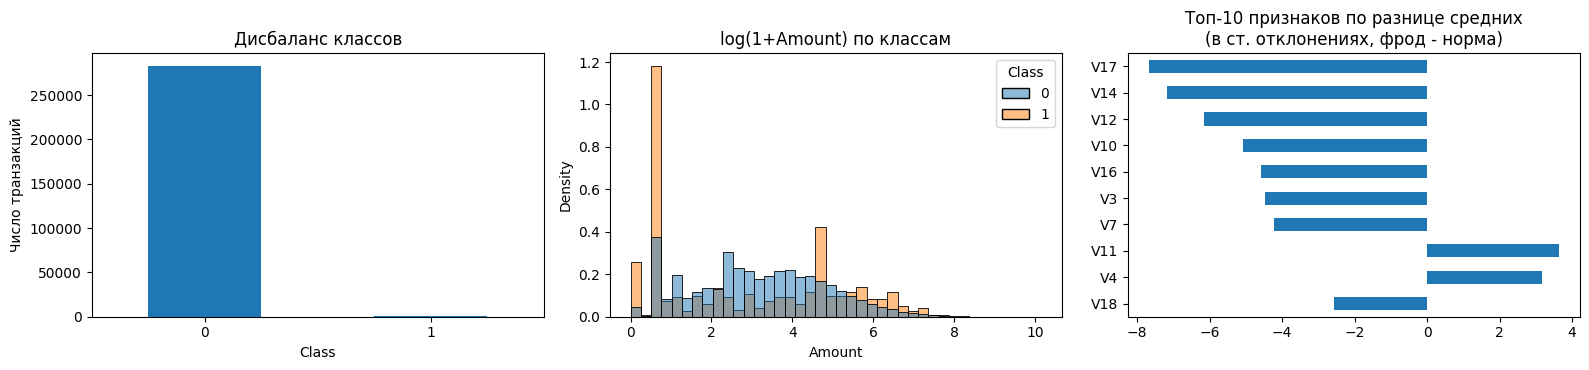

Топ-10 признаков, отличающих фрод от нормы: V17, V14, V12, V10, V16, V3, V7, V11, V4, V18


In [3]:
features = df.drop(columns=[cfg.target])
is_fraud = df[cfg.target] == 1
std_diff = (features[is_fraud].mean() - features[~is_fraud].mean()) / features.std()
top = std_diff.abs().sort_values(ascending=False).head(10).index
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
df[cfg.target].value_counts().plot.bar(ax=ax[0])
ax[0].set(title="Дисбаланс классов", xlabel="Class", ylabel="Число транзакций")
ax[0].tick_params(axis="x", rotation=0)
sns.histplot(data=df, x=np.log1p(df["Amount"]), hue=cfg.target, bins=40, stat="density", common_norm=False, ax=ax[1])
ax[1].set_title("log(1+Amount) по классам")
std_diff[top].plot.barh(ax=ax[2])
ax[2].set_title("Топ-10 признаков по разнице средних\n(в ст. отклонениях, фрод - норма)")
ax[2].invert_yaxis()
plt.tight_layout()
plt.savefig(cfg.results_dir / "eda.png", dpi=150, bbox_inches="tight")
plt.show()

print("Топ-10 признаков, отличающих фрод от нормы:", ", ".join(list(top)))

## 2. Разбиения и предобработка

* `random_indices` — стратифицированное разбиение 70/30; `time_indices` — первые 70% по времени для обучения, последние 30% для теста.
* `make_split` формирует признаки (`Time` исключён, `Amount` без логарифма — управляется `cfg`), обучает `RobustScaler` **только на нормальных транзакциях train** и ограничивает масштабированные значения диапазоном `+-cfg.clip_value` (отсечение тяжёлых хвостов). Для метрики «Сумма@b» хранится исходная сумма.
* `validation_split` делит train на обучение и валидацию для подбора параметров; тест в подборе не участвует.

In [4]:
@dataclass
class Split:
    """Готовые к обучению матрицы одного разбиения."""
    X_train: np.ndarray
    X_test: np.ndarray
    y_train: np.ndarray
    y_test: np.ndarray
    amount_test: np.ndarray          # исходная сумма транзакций test (для метрики «Сумма@b»)
    columns: list

    @property
    def X_normal(self):
        """Нормальные транзакции train — на них обучаются все методы без учителя."""
        return self.X_train[self.y_train == 0]


def random_indices(df, cfg, seed):
    return train_test_split(np.arange(len(df)), test_size=cfg.test_size, stratify=df[cfg.target].values, random_state=seed)


def time_indices(df, cfg):
    order = np.argsort(df["Time"].values, kind="stable")
    cut = int((1 - cfg.test_size) * len(df))
    return order[:cut], order[cut:]


def make_split(df, train_idx, test_idx, cfg):
    """Признаки -> RobustScaler (по норме train) -> отсечение по +-cfg.clip_value. Все настройки берутся из cfg."""
    columns = [c for c in df.columns if c != cfg.target and c not in cfg.drop_cols]

    def features(idx):
        X = df.iloc[idx][columns].copy()
        if cfg.log_amount and "Amount" in columns:
            X["Amount"] = np.log1p(X["Amount"])
        return X

    X_tr, X_te = features(train_idx), features(test_idx)
    y_tr = df.iloc[train_idx][cfg.target].values
    scaler = RobustScaler().fit(X_tr.iloc[y_tr == 0])

    def scale(X):
        Z = scaler.transform(X)
        return np.clip(Z, -cfg.clip_value, cfg.clip_value) if cfg.clip_value else Z

    return Split(scale(X_tr), scale(X_te), y_tr,
                 df.iloc[test_idx][cfg.target].values, df.iloc[test_idx]["Amount"].values, columns)


def validation_split(df, cfg, seed):
    train_idx, _ = random_indices(df, cfg, seed)
    fit_idx, val_idx = train_test_split(train_idx, test_size=cfg.val_size, stratify=df[cfg.target].values[train_idx], random_state=seed)
    return make_split(df, fit_idx, val_idx, cfg)


demo = make_split(df, *random_indices(df, cfg, seed=42), cfg)
print(f"train: {demo.X_train.shape}, test: {demo.X_test.shape}, "
      f"аномалий в test: {demo.y_test.sum()} ({demo.y_test.mean():.3%}), нормальных для обучения: {len(demo.X_normal)}")
print("Признаки:", ", ".join(demo.columns[:3]), "...", ", ".join(demo.columns[-2:]))
if cfg.clip_value:
    at_bound = np.isclose(np.abs(demo.X_train), cfg.clip_value)
    print(f"Отсечение по +-{cfg.clip_value:g}: затронуто {at_bound.mean():.3%} значений train; "
          f"сильнее всего у признаков: {', '.join(pd.Series(at_bound.mean(axis=0), index=demo.columns).nlargest(3).index)}")

train: (198608, 29), test: (85118, 29), аномалий в test: 142 (0.167%), нормальных для обучения: 198277
Признаки: V1, V2, V3 ... V28, Amount
Отсечение по +-10: затронуто 0.225% значений train; сильнее всего у признаков: Amount, V27, V8


## 3. Детекторы

Единый интерфейс: `fit(X)` обучает метод на нормальных транзакциях, `score(X)` возвращает **оценку аномальности** (больше = подозрительнее). Параметры проверяются: опечатка в имени параметра вызывает ошибку, а не молча игнорируется. Обученная модель хранится в самом объекте (`detector.model_`).

* `DETECTORS` — пять методов, для которых подбираются параметры.
* Random Forest — эталон с учителем.

In [5]:
class RobustMahalanobis():
    """Квадрат расстояния Махаланобиса; центр и ковариация — MinCovDet (FastMCD + пересчёт по точкам внутри порога)."""
    name, DEFAULTS = "Robust Mahalanobis", {"support_fraction": 1.0}

    def __init__(self, seed= 0, **params):
            unknown = set(params) - set(self.DEFAULTS)
            if unknown:
                raise TypeError(f"{type(self).__name__}: неизвестные параметры {sorted(unknown)}")
            self.seed = seed
            self.params = {**self.DEFAULTS, **params}

    def fit(self, X):
        self.model_ = MinCovDet(random_state=self.seed, **self.params).fit(X)
        return self

    def score(self, X):
        return self.model_.mahalanobis(X)


class IsolationForestDetector():
    name, DEFAULTS = "Isolation Forest", {"n_estimators": 300, "max_samples": 256}

    def __init__(self, seed = 0, **params):
            unknown = set(params) - set(self.DEFAULTS)
            if unknown:
                raise TypeError(f"{type(self).__name__}: неизвестные параметры {sorted(unknown)}")
            self.seed = seed
            self.params = {**self.DEFAULTS, **params}

    def fit(self, X):
        self.model_ = IsolationForest(random_state=self.seed, n_jobs=-1, **self.params).fit(X)
        return self

    def score(self, X):
        return -self.model_.score_samples(X)


class LOFDetector():
    """Local Outlier Factor в режиме novelty (обучение на норме)."""
    name, DEFAULTS = "LOF", {"n_neighbors": 35}

    def __init__(self, seed = 0, **params):
            unknown = set(params) - set(self.DEFAULTS)
            if unknown:
                raise TypeError(f"{type(self).__name__}: неизвестные параметры {sorted(unknown)}")
            self.seed = seed
            self.params = {**self.DEFAULTS, **params}

    def fit(self, X):
        self.model_ = LocalOutlierFactor(novelty=True, n_jobs=-1, **self.params).fit(X)
        return self

    def score(self, X):
        return -self.model_.score_samples(X)


class KMeansDetector():
    """Расстояние до ближайшего центроида K-means: нормальные транзакции образуют кластеры,
    аномалия лежит далеко от всех центров. Используется MiniBatchKMeans — быстрый вариант алгоритма
    на больших данных."""
    name, DEFAULTS = "K-means", {"n_clusters": 32}

    def __init__(self, seed = 0, **params):
            unknown = set(params) - set(self.DEFAULTS)
            if unknown:
                raise TypeError(f"{type(self).__name__}: неизвестные параметры {sorted(unknown)}")
            self.seed = seed
            self.params = {**self.DEFAULTS, **params}

    def fit(self, X):
        self.model_ = MiniBatchKMeans(n_clusters=self.params["n_clusters"], n_init=3,
                                      batch_size=4096, random_state=self.seed).fit(X)
        return self

    def score(self, X):
        return pairwise_distances_argmin_min(X, self.model_.cluster_centers_)[1]


class AutoEncoder():
    """Автоэнкодер со сжатием на MLPRegressor; оценка = средний квадрат ошибки реконструкции."""
    name, DEFAULTS = "Автоэнкодер", {"hidden": (32, 12, 32)}

    def __init__(self, seed = 0, **params):
            unknown = set(params) - set(self.DEFAULTS)
            if unknown:
                raise TypeError(f"{type(self).__name__}: неизвестные параметры {sorted(unknown)}")
            self.seed = seed
            self.params = {**self.DEFAULTS, **params}

    def fit(self, X):
        bottleneck = min(self.params["hidden"])
        if bottleneck >= X.shape[1]:
            raise ValueError(f"Автоэнкодер обязан сжимать данные: узкое место {bottleneck} должно быть меньше "
                             f"числа признаков {X.shape[1]}")
        self.model_ = MLPRegressor(hidden_layer_sizes=self.params["hidden"], max_iter=500, n_iter_no_change=20,
                                   learning_rate_init=0.001, tol=1e-4, early_stopping=True,
                                   validation_fraction=0.1, random_state=self.seed).fit(X, X)
        return self

    def feature_errors(self, X):
        """Квадраты ошибок реконструкции по признакам."""
        return (X - self.model_.predict(X)) ** 2

    def score(self, X):
        return self.feature_errors(X).mean(axis=1)

DETECTORS = {c.name: c for c in (RobustMahalanobis, IsolationForestDetector, LOFDetector, KMeansDetector, AutoEncoder)}


def reference_scores(split, seed):
    """Эталон с учителем (не метод обнаружения аномалий): Random Forest на размеченном train."""
    rf = RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample", min_samples_leaf=2,
                                n_jobs=-1, random_state=seed).fit(split.X_train, split.y_train)
    return rf.predict_proba(split.X_test)[:, 1]


print("Методы:", list(DETECTORS))

Методы: ['Robust Mahalanobis', 'Isolation Forest', 'LOF', 'K-means', 'Автоэнкодер']


## 4. Метрики

Главная метрика — **PR-AUC** (Average Precision). Практический сценарий: аналитики проверяют долю `b` транзакций с наибольшей оценкой; для `b` из набора {0,1%; 0,5%; 1%} считаются Recall@b, Precision@b (при фиксированном бюджете пропорциональна Recall@b) и «Сумма@b» — доля суммарной стоимости всех фродов, попавших в проверку (зависит от нескольких крупных транзакций и сильно «шумит»). Recall@0,1% ограничен сверху: проверяется около 85 транзакций при около 140 фродах в тесте.

In [6]:
def evaluate(y, s, amount, budgets):
    """ROC-AUC, PR-AUC и метрики при бюджете проверки b (доля транзакций с наибольшей оценкой)."""
    out = {"ROC-AUC": roc_auc_score(y, s), "PR-AUC": average_precision_score(y, s)}
    order = np.argsort(-s, kind="stable")
    n_fraud, fraud_amount = y.sum(), amount[y == 1].sum()
    for b in budgets:
        top = order[:int(round(b * len(y)))]
        out[f"Recall@{b:.1%}"] = y[top].sum() / n_fraud
        out[f"Precision@{b:.1%}"] = y[top].mean()
        out[f"Сумма@{b:.1%}"] = amount[top][y[top] == 1].sum() / fraud_amount
    return out


def recall_at(y, s, b):
    return y[np.argsort(-s, kind="stable")[:int(round(b * len(y)))]].sum() / y.sum()


print("Бюджеты проверки:", [f"{b:.1%}" for b in cfg.budgets])

Бюджеты проверки: ['0.1%', '0.5%', '1.0%']


## 5. Функции эксперимента

Здесь только определения (ничего не запускается):
* подбор параметров — результат возвращается объектом `TuningResult`, а не записывается в глобальные переменные; **дешёвые методы** (`cfg.cheap_methods`) оцениваются на нескольких валидационных разбиениях (`cfg.tune_seeds`) и усредняются, дорогие (LOF, автоэнкодер) — на одном;
* `score_all` — обучить выбранные методы на одном разбиении (общая функция для основного сравнения, разбиения по времени и многосидового прогона);
* `run_random_splits` — прогон по набору seeds; `run_ablation` — абляция признаков;
* статистика: доверительные интервалы и парное сравнение с лучшим методом.

In [7]:
@dataclass
class TuningResult:
    """Результат подбора: таблица перебора и лучшие параметры каждого метода."""
    table: pd.DataFrame
    best: dict

    def update(self, method, params):
        """Новый результат с заменой параметров метода (например, после проверки автоэнкодера на нескольких seeds)."""
        return TuningResult(self.table, {**self.best, method: params})


def fit_score(cls, params, split, seed):
    """Обучает детектор на нормальных транзакциях split и оценивает test; возвращает (оценки, секунды, детектор)."""
    t0 = time.time()
    detector = cls(seed=seed, **params).fit(split.X_normal)
    scores = detector.score(split.X_test)
    return scores, time.time() - t0, detector


def call_counting_mcd(fn, *args, **kwargs):
    """Вызывает fn и считает предупреждения MCD о сходимости; остальные предупреждения показываются как обычно."""
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        result = fn(*args, **kwargs)
    n_mcd = 0
    for w in caught:
        if "Determinant has increased" in str(w.message):
            n_mcd += 1
        else:
            warnings.warn_explicit(w.message, w.category, w.filename, w.lineno)
    return result, n_mcd


def tune(df, cfg, detectors, grids):
    """Перебор сеток по PR-AUC на валидации. Дешёвые методы усредняются по cfg.tune_seeds, дорогие — один seed."""
    val_splits = {s: validation_split(df, cfg, s) for s in cfg.tune_seeds}
    rows = []
    for name, cls in detectors.items():
        is_cheap = name in cfg.cheap_methods
        seeds = cfg.tune_seeds if is_cheap else cfg.tune_seeds[:1]
        for params in grids.get(name, [{}]):
            pr, roc, secs, n_mcd = [], [], [], 0
            for s in seeds:
                val = val_splits[s]
                (scores, sec, _), w = call_counting_mcd(fit_score, cls, params, val, s)
                pr.append(average_precision_score(val.y_test, scores))
                roc.append(roc_auc_score(val.y_test, scores))
                secs.append(sec)
                n_mcd += w
            rows.append({"Метод": name, "Параметры": str(params), "params": params,
                         "PR-AUC (val)": np.mean(pr), "± ст.откл.": np.std(pr, ddof=1) if len(pr) > 1 else np.nan,
                         "ROC-AUC (val)": np.mean(roc), "Время, с": np.mean(secs),
                         "Предупр. MCD": n_mcd, "Seeds": len(seeds)})
    table = pd.DataFrame(rows)
    best = {n: g.sort_values("PR-AUC (val)", ascending=False).iloc[0]["params"] for n, g in table.groupby("Метод")}
    return TuningResult(table, best)


def check_grid_edges(tuning, names):
    """Для одномерных сеток сообщает, лежит ли лучший вариант на краю (плато или не найден оптимум)."""
    for name in names:
        sub = tuning.table[tuning.table["Метод"] == name].reset_index(drop=True)
        i = sub["params"].tolist().index(tuning.best[name])
        if i in (0, len(sub) - 1):
            j = 1 if i == 0 else len(sub) - 2
            gap = sub.loc[i, "PR-AUC (val)"] - sub.loc[j, "PR-AUC (val)"]
            verdict = "плато (сосед почти не хуже)" if gap < 0.01 else "оптимум не найден, расширьте сетку"
            print(f"Внимание, {name}: лучший вариант на краю сетки {tuning.best[name]}, разница с соседом {gap:+.4f}: {verdict}")
        else:
            print(f"{name}: оптимум внутри сетки ({tuning.best[name]})")

 
def check_seeds(cls, candidates, val, seeds):
    """Среднее и разброс PR-AUC на валидации по нескольким seeds (меняется инициализация) для каждой конфигурации."""
    rows = []
    for params in candidates:
        pr = [average_precision_score(val.y_test, fit_score(cls, params, val, sd)[0]) for sd in seeds]
        rows.append({"params": params, "mean": np.mean(pr), "std": np.std(pr, ddof=1),
                     **{f"seed {sd}": v for sd, v in zip(seeds, pr)}})
    return pd.DataFrame(rows).sort_values("mean", ascending=False).reset_index(drop=True)

In [8]:
@dataclass
class Scored:
    """Оценки аномальности, время и обученные детекторы одного разбиения."""
    scores: dict
    seconds: dict
    fitted: dict


def score_all(split, tuning, seed, methods = None, with_reference = True):
    """Обучает выбранные методы (по умолчанию все) на одном разбиении, затем эталон."""
    pool = DETECTORS
    chosen = pool if methods is None else {n: pool[n] for n in methods}
    scores, secs, fitted = {}, {}, {}
    for name, cls in chosen.items():
        scores[name], secs[name], fitted[name] = fit_score(cls, tuning.best.get(name, {}), split, seed)
    if with_reference:
        t0 = time.time()
        scores["Random Forest"] = reference_scores(split, seed)
        secs["Random Forest"] = time.time() - t0
    return Scored(scores, secs, fitted)


def metrics_table(scored, split, cfg, **extra):
    rows = [{**extra, "Метод": name, **evaluate(split.y_test, s, split.amount_test, cfg.budgets),
             "Время, с": scored.seconds[name]} for name, s in scored.scores.items()]
    return pd.DataFrame(rows)


def run_random_splits(df, cfg, tuning, seeds,
                      methods = None,
                      with_reference = True, keep_seed = None):
    """Прогон по набору seeds. Возвращает (таблицу метрик, (split, scored) для keep_seed или None)."""
    tables, kept = [], None
    for seed in seeds:
        train_idx, test_idx = random_indices(df, cfg, seed)
        split = make_split(df, train_idx, test_idx, cfg)
        scored = score_all(split, tuning, seed, methods, with_reference)
        tables.append(metrics_table(scored, split, cfg, seed=seed))
        if seed == keep_seed:
            kept = (split, scored)
        print(f"seed {seed}: готово (фродов в test: {split.y_test.sum()})")
    return pd.concat(tables, ignore_index=True), kept


def run_time_split(df, cfg, tuning, seed = 42):
    """Обучение на первых 70% транзакций по времени, проверка на последних 30%."""
    train_idx, test_idx = time_indices(df, cfg)
    split = make_split(df, train_idx, test_idx, cfg)
    return metrics_table(score_all(split, tuning, seed), split, cfg).set_index("Метод"), split


def ablation_variants(cfg):
    """Варианты предобработки: каждый отличается от базовой конфигурации одним фактором."""
    variants = {"без отсечения": replace(cfg, clip_value=None)}
    for bound in (5.0, 10.0, 20.0, 50.0):
        variants[f"отсечение {bound:g}"] = replace(cfg, clip_value=bound)
    variants["с Time"] = replace(cfg, drop_cols=())
    variants["log1p(Amount)"] = replace(cfg, log_amount=True)
    return variants


def run_ablation(df, cfg, grids):
    """PR-AUC методов из cfg.ablation_methods для каждого варианта предобработки.
    Параметры подбираются заново для каждого варианта (одно валидационное разбиение), чтобы сравнение
    не было смещено в пользу конфигурации, при которой параметры выбирались в разделе 6."""
    pool = DETECTORS
    detectors = {n: DETECTORS[n] for n in cfg.ablation_methods if n in DETECTORS}
    rows = []
    for label, variant in ablation_variants(cfg).items():
        tuned = tune(df, replace(variant, tune_seeds=cfg.tune_seeds[:1]), detectors, grids)
        for seed in cfg.ablation_seeds:
            train_idx, test_idx = random_indices(df, variant, seed)
            split = make_split(df, train_idx, test_idx, variant)
            for name in cfg.ablation_methods:
                scores, _, _ = fit_score(pool[name], tuned.best.get(name, {}), split, seed)
                rows.append({"seed": seed, "Вариант": label, "Метод": name,
                             "PR-AUC": average_precision_score(split.y_test, scores),
                             "Параметры": str(tuned.best.get(name, {}))})
        print(f"Вариант '{label}': готово")
    return pd.DataFrame(rows)


def ci95(values):
    """Полуширина 95% доверительного интервала среднего (t-распределение)."""
    x = np.asarray(values, dtype=float)
    return stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else float("nan")


def mean_std_table(runs, cols):
    g = runs.groupby("Метод", sort=False)[list(cols)]
    mean, std = g.mean(), g.std()
    return pd.DataFrame({c: [f"{mean.loc[m, c]:.3f} ± {std.loc[m, c]:.3f}" for m in mean.index] for c in cols},
                        index=mean.index)


def interval_table(runs, col = "PR-AUC"):
    """Среднее и 95% доверительный интервал среднего по разбиениям для каждого метода."""
    rows = {}
    for method, g in runs.groupby("Метод", sort=False)[col]:
        h = ci95(g)
        rows[method] = {"разбиений": len(g), "среднее": f"{g.mean():.3f}", "95% ДИ": f"[{g.mean() - h:.3f}; {g.mean() + h:.3f}]"}
    return pd.DataFrame(rows).T


def paired_vs_best(runs, names, col = "PR-AUC"):
    """Лучший по среднему метод и парное сравнение с ним по общим разбиениям: победы, средняя разница, 95% ДИ."""
    pivot = runs.pivot(index="seed", columns="Метод", values=col)[list(names)].dropna()
    best = pivot.mean().idxmax()
    rows = []
    for m in names:
        if m == best:
            continue
        d = pivot[best] - pivot[m]
        h = ci95(d)
        rows.append({"Метод": m, "Лучший лучше на": f"{int((d > 0).sum())} из {len(d)}",
                     "Средняя разница": f"{d.mean():+.3f}", "95% ДИ разницы": f"[{d.mean() - h:+.3f}; {d.mean() + h:+.3f}]"})
    return best, pd.DataFrame(rows).set_index("Метод")

## 6. Подбор гиперпараметров

Тренировочная часть каждого разбиения делится на обучение (75%) и **валидацию** (25%); критерий — PR-AUC на валидации, тест не используется. Для дешёвых методов результат усредняется по `cfg.tune_seeds`, столбец «± ст.откл.» показывает разброс между разбиениями.

* У робастного Махаланобиса `support_fraction=1.0` — естественный максимум. Резкое падение при 0,95 сопровождается предупреждениями «Determinant has increased» (столбец «Предупр. MCD»): это численный сбой FastMCD, значение в этой точке интерпретировать не следует.
* Для одномерных сеток (LOF, K-means) после таблицы выводится проверка, не лежит ли оптимум на краю сетки.
* Все архитектуры автоэнкодера в сетке имеют узкое место меньше числа признаков; это проверяется в `AutoEncoder.fit`.

In [9]:
GRIDS = {
        "Robust Mahalanobis": [{"support_fraction": v} for v in (0.95, 0.99, 1.0)],
        "Isolation Forest":   [{"max_samples": v} for v in (0.25, 0.5, 0.75, 1.0)],
        "LOF":                [{"n_neighbors": v} for v in (250, 400, 600, 800, 1200)],
        "K-means":            [{"n_clusters": v} for v in (128, 256, 512, 1024)],
        "Автоэнкодер":        [{"hidden": v} for v in ((64, 8, 64), (64, 12, 64), (64, 16, 64),
                                                       (128, 16, 128), (128, 20, 128), (128, 24, 128),
                                                       (128, 16, 8, 16, 128))],
    }

tuning = tune(df, cfg, DETECTORS, GRIDS)

table = tuning.table.drop(columns="params").round(4)
table["Выбран"] = ["да" if p == tuning.best[m] else "" for m, p in zip(tuning.table["Метод"], tuning.table["params"])]
print(table.to_string(index=False))
print("\nВыбранные параметры:", tuning.best)
print()
check_grid_edges(tuning, ("LOF", "K-means"))
table.to_csv(cfg.results_dir / "tuning.csv", index=False)

             Метод                         Параметры  PR-AUC (val)  ± ст.откл.  ROC-AUC (val)  Время, с  Предупр. MCD  Seeds Выбран
Robust Mahalanobis        {'support_fraction': 0.95}        0.6632      0.0641         0.9538   37.0206             0      3       
Robust Mahalanobis        {'support_fraction': 0.99}        0.6633      0.0642         0.9565   26.5282             0      3       
Robust Mahalanobis         {'support_fraction': 1.0}        0.6636      0.0626         0.9580   18.6534             0      3     да
  Isolation Forest             {'max_samples': 0.25}        0.3276      0.0747         0.9589    2.9103             0      3       
  Isolation Forest              {'max_samples': 0.5}        0.3593      0.0695         0.9585    3.7863             0      3       
  Isolation Forest             {'max_samples': 0.75}        0.3643      0.0542         0.9574    4.5284             0      3       
  Isolation Forest              {'max_samples': 1.0}        0.3770      0.05

### 6.1 Проверка архитектуры автоэнкодера на нескольких seeds

Автоэнкодер зависит от инициализации, а валидация содержит всего около 80 фродов, поэтому выбор по одному seed шумный. Три лучшие по валидации архитектуры обучаются на `cfg.ae_check_seeds`, выбирается лучшая **по среднему**; `TuningResult` обновляется.

In [10]:
val_main = validation_split(df, cfg, cfg.tune_seeds[0])
ae_check = None
if cfg.run_ae_seed_check:
    top3 = tuning.table[tuning.table["Метод"] == AutoEncoder.name].nlargest(3, "PR-AUC (val)")["params"].tolist()
    ae_check = check_seeds(AutoEncoder, top3, val_main, cfg.ae_check_seeds)
    print(ae_check.round(4).to_string(index=False))
    chosen = ae_check.iloc[0]
    tuning = tuning.update(AutoEncoder.name, chosen["params"])
    ae_check.round(4).to_csv(cfg.results_dir / "ae_seed_check.csv", index=False)
else:
    print("Проверка на нескольких seeds отключена (cfg.run_ae_seed_check = False)")

print(f"\nИтоговая архитектура автоэнкодера: {tuning.best[AutoEncoder.name]['hidden']}")

                           params   mean    std  seed 42  seed 7  seed 13
       {'hidden': (128, 24, 128)} 0.6090 0.0437   0.5661  0.6535   0.6074
{'hidden': (128, 16, 8, 16, 128)} 0.5005 0.0550   0.5562  0.4462   0.4991
         {'hidden': (64, 12, 64)} 0.4906 0.0716   0.5382  0.4083   0.5254

Итоговая архитектура автоэнкодера: (128, 24, 128)


## 7. Итоговое сравнение

* **7.0.** Все методы на `cfg.seeds` (5 разбиений).
* **7.1.** Дешёвые методы (`cfg.cheap_methods` и эталон) дополнительно на `cfg.extra_seeds`; вместе получается `len(cfg.cheap_seeds)` разбиений, что даёт доверительные интервалы. Результаты для общих seeds не пересчитываются, а берутся из 7.0 (методы детерминированы по seed). Доверительные интервалы оптимистичны: тестовые выборки разных seeds пересекаются.

In [11]:
MAIN_COLS = ["ROC-AUC", "PR-AUC", "Recall@0.1%", "Recall@0.5%", "Recall@1.0%", "Время, с"]
EXTRA_COLS = ["Precision@0.1%", "Precision@0.5%", "Precision@1.0%", "Сумма@0.1%", "Сумма@0.5%", "Сумма@1.0%"]

runs_main, (split_main, scored_main) = run_random_splits(df, cfg, tuning, cfg.seeds, keep_seed=cfg.seeds[0])
runs_main.to_csv(cfg.results_dir / "metrics_all_runs.csv", index=False)


print(f"\nТаблица A. Основные метрики (среднее ± ст. откл., {len(cfg.seeds)} разбиений)")
print(mean_std_table(runs_main, MAIN_COLS).to_string())
print("\nТаблица B. Precision и доля суммы фрода при бюджете проверки")
print(mean_std_table(runs_main, EXTRA_COLS).to_string())
sum_table = runs_main.groupby("Метод", sort=False)[MAIN_COLS + EXTRA_COLS].agg(["mean", "std"]).round(4)
sum_table.to_csv(cfg.results_dir / "metrics_summary.csv")

best_main, paired_main = paired_vs_best(runs_main, [m for m in runs_main["Метод"].unique() if m != "Random Forest"])
print(f"\nПарное сравнение по PR-AUC с лучшим методом без разметки — {best_main}:")
print(paired_main.to_string())

seed 42: готово (фродов в test: 142)
seed 1: готово (фродов в test: 142)
seed 2: готово (фродов в test: 142)
seed 3: готово (фродов в test: 142)
seed 4: готово (фродов в test: 142)

Таблица A. Основные метрики (среднее ± ст. откл., 5 разбиений)
                          ROC-AUC         PR-AUC    Recall@0.1%    Recall@0.5%    Recall@1.0%          Время, с
Метод                                                                                                          
Robust Mahalanobis  0.947 ± 0.006  0.665 ± 0.018  0.518 ± 0.011  0.762 ± 0.016  0.766 ± 0.014    22.022 ± 1.725
Isolation Forest    0.943 ± 0.006  0.346 ± 0.040  0.290 ± 0.024  0.576 ± 0.027  0.682 ± 0.029     6.634 ± 0.043
LOF                 0.924 ± 0.014  0.563 ± 0.030  0.477 ± 0.014  0.745 ± 0.025  0.768 ± 0.019    50.529 ± 0.289
K-means             0.937 ± 0.007  0.358 ± 0.091  0.286 ± 0.085  0.634 ± 0.065  0.754 ± 0.026     0.839 ± 0.023
Автоэнкодер         0.940 ± 0.007  0.545 ± 0.075  0.415 ± 0.039  0.756 ± 0.033  0.7

In [12]:
extra_runs, _ = run_random_splits(df, cfg, tuning, cfg.extra_seeds, methods=cfg.cheap_methods)
runs_cheap = pd.concat([runs_main[runs_main["Метод"].isin(list(cfg.cheap_methods) + ["Random Forest"])], extra_runs], ignore_index=True)
runs_cheap.to_csv(cfg.results_dir / "metrics_cheap_runs.csv", index=False)

n_cheap = runs_cheap["seed"].nunique()
print(f"\nТаблица C. Дешёвые методы и эталон на {n_cheap} разбиениях")
print(mean_std_table(runs_cheap, ["ROC-AUC", "PR-AUC", "Recall@0.5%", "Время, с"]).to_string())
print("\nPR-AUC: среднее и 95% доверительный интервал среднего")
print(interval_table(runs_cheap).to_string())

best_cheap, paired_cheap = paired_vs_best(runs_cheap, cfg.cheap_methods)
print(f"\nПарное сравнение по PR-AUC с лучшим из дешёвых методов — {best_cheap}:")
print(paired_cheap.to_string())

seed 10: готово (фродов в test: 142)
seed 11: готово (фродов в test: 142)
seed 12: готово (фродов в test: 142)
seed 13: готово (фродов в test: 142)
seed 14: готово (фродов в test: 142)
seed 15: готово (фродов в test: 142)
seed 16: готово (фродов в test: 142)
seed 17: готово (фродов в test: 142)
seed 18: готово (фродов в test: 142)
seed 19: готово (фродов в test: 142)
seed 20: готово (фродов в test: 142)
seed 21: готово (фродов в test: 142)
seed 22: готово (фродов в test: 142)
seed 23: готово (фродов в test: 142)
seed 24: готово (фродов в test: 142)

Таблица C. Дешёвые методы и эталон на 20 разбиениях
                          ROC-AUC         PR-AUC    Recall@0.5%        Время, с
Метод                                                                          
Robust Mahalanobis  0.954 ± 0.008  0.679 ± 0.026  0.787 ± 0.028  22.622 ± 1.626
Isolation Forest    0.952 ± 0.009  0.369 ± 0.036  0.608 ± 0.040   6.526 ± 0.089
K-means             0.948 ± 0.009  0.382 ± 0.087  0.651 ± 0.056   0.873 

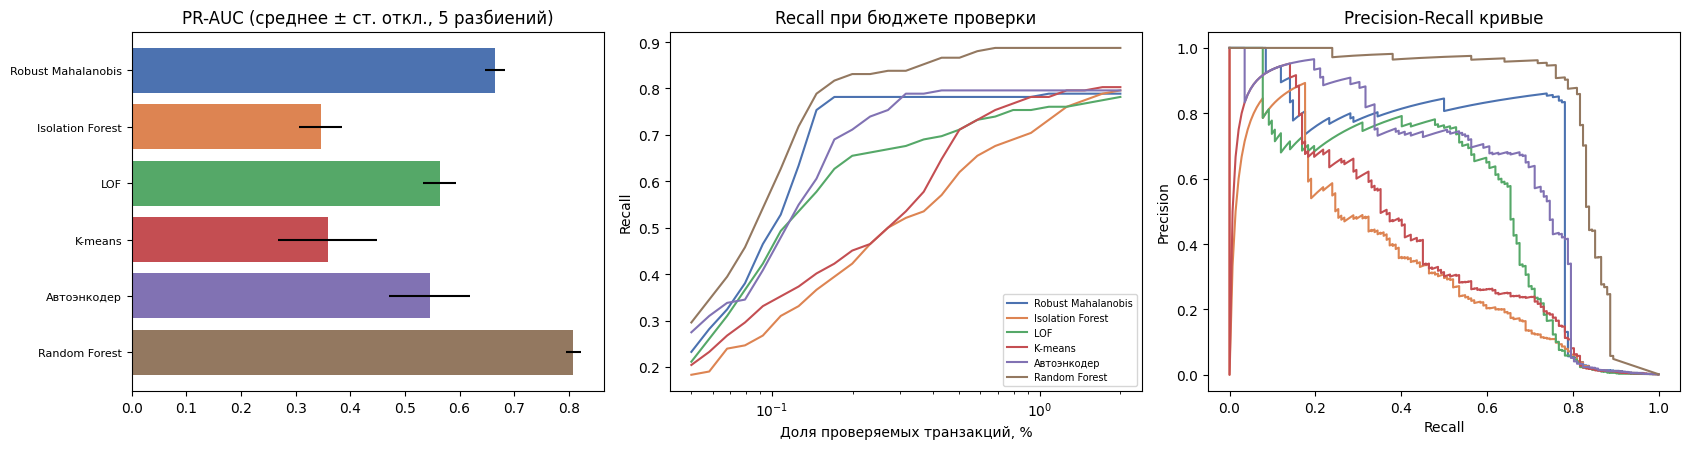

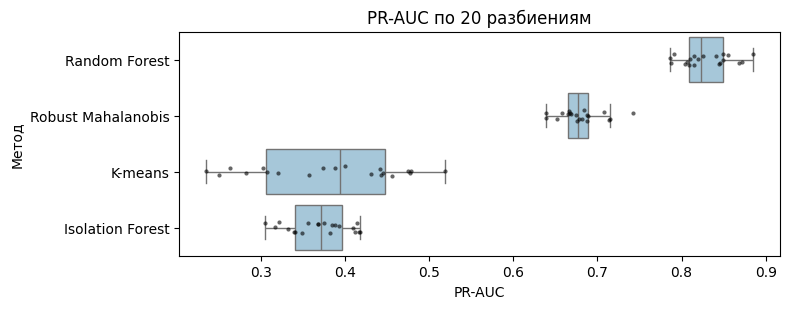

In [13]:
"""PR-AUC по разбиениям, Recall от бюджета проверки и PR-кривые (для первого seed)."""
names = list(runs_main["Метод"].unique())
palette = dict(zip(names, sns.color_palette("deep", len(names))))
y = split_main.y_test
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
g = runs_main.groupby("Метод", sort=False)["PR-AUC"]
ax[0].barh(range(len(names)), g.mean().values, xerr=g.std().values, color=[palette[n] for n in names])
ax[0].set_yticks(range(len(names)))
ax[0].set_yticklabels([n.replace(" (", "\n(") for n in names], fontsize=8)
ax[0].invert_yaxis()
ax[0].set_title(f"PR-AUC (среднее ± ст. откл., {runs_main['seed'].nunique()} разбиений)")
budgets = np.geomspace(0.0005, 0.02, 25)
for n in names:
    ax[1].plot(budgets * 100, [recall_at(y, scored_main.scores[n], b) for b in budgets], label=n, color=palette[n])
ax[1].set_xscale("log")
ax[1].set(xlabel="Доля проверяемых транзакций, %", ylabel="Recall", title="Recall при бюджете проверки")
ax[1].legend(fontsize=7)
for n in names:
    precision, recall, _ = precision_recall_curve(y, scored_main.scores[n])
    ax[2].plot(recall, precision, label=n, color=palette[n])
ax[2].set(title="Precision-Recall кривые", xlabel="Recall", ylabel="Precision")
plt.tight_layout()
plt.savefig(cfg.results_dir / "comparison.png", dpi=150, bbox_inches="tight")
plt.show()


"""Разброс PR-AUC дешёвых методов по разбиениям."""
order = runs_cheap.groupby("Метод")["PR-AUC"].mean().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(8, 3.2))
sns.boxplot(data=runs_cheap, x="PR-AUC", y="Метод", order=order, ax=ax, color="#9ecae1", fliersize=0)
sns.stripplot(data=runs_cheap, x="PR-AUC", y="Метод", order=order, ax=ax, color="black", size=3, alpha=0.6)
ax.set_title(f"PR-AUC по {runs_cheap['seed'].nunique()} разбиениям")
plt.tight_layout()
plt.savefig(cfg.results_dir / "cheap_distribution.png", dpi=150, bbox_inches="tight")
plt.show()


## 8. Абляция признаков: `Time`, `log1p(Amount)` и отсечение хвостов

Проверяется, как меняют качество наличие `Time`, логарифмирование `Amount` и отсечение масштабированных значений: PR-AUC для вариантов, каждый из которых отличается от базовой конфигурации одним фактором: граница отсечения (без отсечения, 5, 10, 20, 50), `Time`, `log1p(Amount)` (методы из `cfg.ablation_methods`, разбиения `cfg.ablation_seeds`, параметры подбираются заново для каждого варианта). LOF и автоэнкодер не включены из-за времени расчёта. Различия порядка стандартного отклонения по разбиениям считаются шумом. Робастный Махаланобис нечувствителен к хвосту `Amount`, поскольку MCD отсекает выбросы.

In [14]:
ablation = run_ablation(df, cfg, GRIDS)
variant_order = list(ablation_variants(cfg))
for title, aggfunc in ((f"PR-AUC, среднее по {len(cfg.ablation_seeds)} разбиениям", "mean"),
                       ("Стандартное отклонение по разбиениям", "std")):
    ablation_table = ablation.pivot_table(index="Метод", columns="Вариант", values="PR-AUC", aggfunc=aggfunc)[variant_order]
    print(f"\n{title}\n{ablation_table.round(3).to_string()}")
ablation.to_csv(cfg.results_dir / "ablation.csv", index=False)

Вариант 'без отсечения': готово
Вариант 'отсечение 5': готово
Вариант 'отсечение 10': готово
Вариант 'отсечение 20': готово
Вариант 'отсечение 50': готово
Вариант 'с Time': готово
Вариант 'log1p(Amount)': готово

PR-AUC, среднее по 3 разбиениям
Вариант             без отсечения  отсечение 5  отсечение 10  отсечение 20  отсечение 50  с Time  log1p(Amount)
Метод                                                                                                          
Isolation Forest            0.313        0.414         0.325         0.272         0.278   0.316          0.325
K-means                     0.100        0.371         0.361         0.206         0.125   0.363          0.316
Robust Mahalanobis          0.671        0.661         0.657         0.663         0.670   0.656          0.657

Стандартное отклонение по разбиениям
Вариант             без отсечения  отсечение 5  отсечение 10  отсечение 20  отсечение 50  с Time  log1p(Amount)
Метод                                        

## 9. Разбиение по времени

Модель обучается на первых 70% транзакций по времени и проверяется на последних 30%. Набор признаков и предобработка те же, что и при случайном разбиении. Ограничения: один seed, около 100 фродов в тесте, один период наблюдения; гиперпараметры подобраны на случайной (перемешанной по времени) валидации, поэтому различия между близкими методами значимыми не считаются.

### Справка: зачем нужно разбиение по времени

* В реальной системе модель обучают на прошлом и применяют к будущему. Случайное разбиение перемешивает периоды: «будущие» транзакции попадают в train, распределения в train и test совпадают, и оценка оптимистична.
* Схемы мошенничества и поведение клиентов меняются со временем (дрейф), поэтому метод должен быть устойчив к сдвигу.
* Это единственная проверка в проекте, которая показывает такую устойчивость; методы здесь ведут себя по-разному.

In [15]:
time_table, split_time = run_time_split(df, cfg, tuning)
print(f"train: {len(split_time.y_train)}, test: {len(split_time.y_test)}, "
      f"фродов в train: {split_time.y_train.sum()}, в test: {split_time.y_test.sum()}")
print(time_table[["ROC-AUC", "PR-AUC", "Recall@0.1%", "Recall@0.5%", "Recall@1.0%", "Сумма@0.5%"]].round(3).to_string())
comparison = pd.DataFrame({
    "PR-AUC (случайное, ср.)": runs_main.groupby("Метод", sort=False)["PR-AUC"].mean(),
    "PR-AUC (по времени)": time_table["PR-AUC"],
}).round(3)
print("\nСравнение со случайным разбиением:")
print(comparison.to_string())
time_table.round(4).to_csv(cfg.results_dir / "metrics_time_split.csv")

train: 198608, test: 85118, фродов в train: 366, в test: 107
                    ROC-AUC  PR-AUC  Recall@0.1%  Recall@0.5%  Recall@1.0%  Сумма@0.5%
Метод                                                                                 
Robust Mahalanobis    0.952   0.739        0.720        0.776        0.776       0.826
Isolation Forest      0.946   0.100        0.075        0.514        0.636       0.656
LOF                   0.939   0.674        0.607        0.766        0.794       0.737
K-means               0.938   0.107        0.084        0.533        0.738       0.541
Автоэнкодер           0.929   0.383        0.439        0.766        0.785       0.823
Random Forest         0.936   0.814        0.757        0.850        0.850       0.896

Сравнение со случайным разбиением:
                    PR-AUC (случайное, ср.)  PR-AUC (по времени)
Метод                                                           
Robust Mahalanobis                    0.665                0.739
Isolation Fo

## 10. Анализ ошибок

На тестовой выборке первого seed при бюджете 0,5% смотрим, какие мошеннические транзакции находят разные методы и какие не находит ни один. В анализ входят методы из `DETECTORS`. Медиана `Amount` пропущенных фродов и вклад признаков в ошибку автоэнкодера **нестабильны** (меняются при смене архитектуры и разбиения), поэтому выводятся справочно.

Бюджет: 426 транзакций (0.5%), фродов в test: 142

Сколько из 5 методов находят каждый фрод:
               0  1  2   3   4   5
число фродов  28  2  1  10  25  76

Находит метод (всего) / только он один:
  Robust Mahalanobis    111 / 0
  Isolation Forest       88 / 0
  LOF                   101 / 1
  K-means               101 / 0
  Автоэнкодер           113 / 1

Пропущены всеми методами: 28 из 142
                                        Пропущены всеми  Найдены хотя бы одним методом
число                                             28.00                         114.00
медиана Amount                                     2.00                          27.60
медиана среднего |V| (после скейлинга)             0.87                           2.62

Признаки с наибольшим вкладом в ошибку реконструкции автоэнкодера (на фродах; справочно, нестабильно):
V17    10.7%
V9      8.3%
V12     7.9%
V10     6.8%
V13     6.2%
V7      5.8%


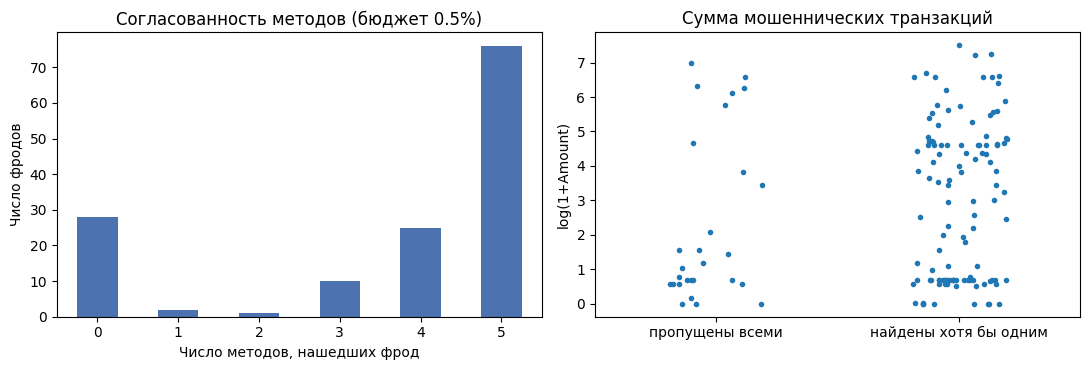

In [ ]:
"""Какие фроды находят методы при бюджете проверки, какие пропущены всеми; график согласованности методов."""
budget = 0.005                                     # доля транзакций, доступная для проверки
y, amount = split_main.y_test, split_main.amount_test
k = int(round(budget * len(y)))
caught = {n: set(np.argsort(-scored_main.scores[n], kind="stable")[:k]) for n in list(DETECTORS)}
fraud_pos = np.where(y == 1)[0]
n_caught = np.array([sum(p in caught[m] for m in list(DETECTORS)) for p in fraud_pos])
missed = n_caught == 0
median = lambda a: float(np.median(a)) if len(a) else float("nan")
print(f"Бюджет: {k} транзакций ({budget:.1%}), фродов в test: {len(fraud_pos)}")
by_count = pd.Series(n_caught).value_counts().reindex(range(len(list(DETECTORS)) + 1), fill_value=0)
print(f"\nСколько из {len(list(DETECTORS))} методов находят каждый фрод:")
print(by_count.rename("число фродов").to_frame().T.to_string())
print("\nНаходит метод (всего) / только он один:")
per_method = {}
for m in list(DETECTORS):
    total = sum(p in caught[m] for p in fraud_pos)
    only = sum(1 for j, p in enumerate(fraud_pos) if p in caught[m] and n_caught[j] == 1)
    per_method[m] = (total, only)
    print(f"  {m:20s} {total:4d} / {only}")
v_idx = [i for i, c in enumerate(split_main.columns) if c.startswith("V")]
X_fraud = split_main.X_test[fraud_pos]
mean_abs_v = np.abs(X_fraud[:, v_idx]).mean(axis=1)
print(f"\nПропущены всеми методами: {missed.sum()} из {len(fraud_pos)}")
print(pd.DataFrame({
    "Пропущены всеми": [missed.sum(), median(amount[fraud_pos][missed]), median(mean_abs_v[missed])],
    "Найдены хотя бы одним методом": [(~missed).sum(), median(amount[fraud_pos][~missed]), median(mean_abs_v[~missed])],
}, index=["число", "медиана Amount", "медиана среднего |V| (после скейлинга)"]).round(2).to_string())
autoencoder = scored_main.fitted.get(AutoEncoder.name)
if autoencoder is not None:
    errors = autoencoder.feature_errors(X_fraud)
    share = errors.mean(axis=0) / errors.mean(axis=0).sum()
    top = pd.Series(share, index=split_main.columns).sort_values(ascending=False).head(6)
    print("\nПризнаки с наибольшим вкладом в ошибку реконструкции автоэнкодера (на фродах; справочно, нестабильно):")
    print((top * 100).round(1).astype(str).add("%").to_string())
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
by_count.plot.bar(ax=ax[0])
ax[0].set(xlabel="Число методов, нашедших фрод", ylabel="Число фродов",
          title=f"Согласованность методов (бюджет {budget:.1%})")
ax[0].tick_params(axis="x", rotation=0)
groups = np.where(missed, "пропущены всеми", "найдены хотя бы одним")
sns.stripplot(x=groups, y=np.log1p(amount[fraud_pos]), ax=ax[1], jitter=0.2, size=4)
ax[1].set(ylabel="log(1+Amount)", title="Сумма мошеннических транзакций")
plt.tight_layout()
plt.savefig(cfg.results_dir / "error_analysis.png", dpi=150, bbox_inches="tight")
plt.show()